# Storyboard → ControlNet baseline pipeline

Step 1 of the project: a shared input pipeline that turns storyboard panels into layout-conditioning maps and generates one frame per panel with ControlNet.

**Before running:** Runtime → Change runtime type → **T4 GPU**.

Sections:
1. Setup and config
2. Panel cropping helpers
3. Conditioning map extraction
4. Load ControlNet
5. Sequence generation loop (saves outputs + config)
6. Side-by-side preview
7. Character reference crops
8. Hooks for the other methods

*Note: this notebook has not been run end to end. Model repo names on Hugging Face change occasionally, so if a download fails, check the current name.*

In [ ]:
!pip install -q diffusers transformers accelerate opencv-python pymupdf
!pip install -U torchao


## 1. Setup and config
Add the shared storyboard folder as a shortcut in My Drive (Drive → right-click folder → Organize → Add shortcut), then set the paths below.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os, json, glob, time
import numpy as np
import cv2
import torch
from PIL import Image
import matplotlib.pyplot as plt

# ---- EDIT THESE ----
PDF_PATH       = '/content/drive/MyDrive/StoryBoard/Evicted-Storyboard.pdf'   # the source PDF
STORYBOARD_DIR = '/content/drive/MyDrive/project/pages'                       # PDF pages rendered to PNG
PANEL_DIR      = '/content/drive/MyDrive/project/panels'         # cropped panels land here
OUTPUT_DIR     = '/content/drive/MyDrive/project/outputs'        # generated frames land here
REF_DIR        = '/content/drive/MyDrive/project/char_refs'      # character reference crops
for d in (STORYBOARD_DIR, PANEL_DIR, OUTPUT_DIR, REF_DIR):
    os.makedirs(d, exist_ok=True)

# One config used for every method so the comparison stays fair
CONFIG = {
    "base_model": "stable-diffusion-v1-5/stable-diffusion-v1-5",
    "controlnet": "lllyasviel/control_v11p_sd15_canny",
    "resolution": 512,
    "steps": 30,
    "guidance_scale": 7.5,
    "controlnet_conditioning_scale": 1.0,
    "seed": 42,
    "cond_mode": "canny",            # "canny" or "invert"
    "canny_low": 100,
    "canny_high": 200,
    "prompt_suffix": "clean colored animation frame, consistent character design",
    "negative_prompt": "blurry, low quality, deformed, extra limbs, text, watermark",
}
print('PDF exists:', os.path.exists(PDF_PATH))

PDF exists: True


### Render the PDF pages to images
The source storyboard is a PDF, so render each page to a PNG first. 200 DPI is a good starting point (higher keeps more line detail but makes files larger). Set `FIRST_PAGE`/`LAST_PAGE` (1-indexed) if the PDF holds more than you need.

In [ ]:
import pymupdf  # PyMuPDF

DPI = 200
FIRST_PAGE, LAST_PAGE = 9, 11   # None = through the last page

doc = pymupdf.open(PDF_PATH)
print('pages in PDF:', len(doc))
last = LAST_PAGE or len(doc)
zoom = DPI / 72
for pno in range(FIRST_PAGE - 1, last):
    pix = doc[pno].get_pixmap(matrix=pymupdf.Matrix(zoom, zoom), alpha=False)
    pix.save(os.path.join(STORYBOARD_DIR, f'page{pno+1:03d}.png'))
print('saved pages to', STORYBOARD_DIR)

pages in PDF: 303
saved pages to /content/drive/MyDrive/project/pages


*Optional:* if the PDF pages are scans or embedded images, you can pull the embedded images at their original resolution instead of re-rendering, using `doc[pno].get_images()` and `doc.extract_image(xref)`. Rendering is simpler and works for any PDF, so start there.

## 2. Panel cropping helpers
Storyboard pages often hold several panels. Use whichever approach fits your files. Crop first, resize later.

In [ ]:
def load_rgb(path):
    return Image.open(path).convert('RGB')   # drops alpha channels that break things downstream

def split_grid(img, rows, cols, margin=0):
    """Evenly split a page into rows x cols panels (reading order)."""
    w, h = img.size
    pw, ph = w // cols, h // rows
    panels = []
    for r in range(rows):
        for c in range(cols):
            box = (c*pw + margin, r*ph + margin, (c+1)*pw - margin, (r+1)*ph - margin)
            panels.append(img.crop(box))
    return panels

def detect_panels(img, min_w=150, min_h=100, thresh_val=200, row_tol=50):
    """Rough auto-detection via contours. Works only if panels have visible borders.
    Always check the result visually."""
    gray = cv2.cvtColor(np.array(img), cv2.COLOR_RGB2GRAY)
    _, thresh = cv2.threshold(gray, thresh_val, 255, cv2.THRESH_BINARY_INV)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    boxes = []
    for c in contours:
        x, y, w, h = cv2.boundingRect(c)
        if w > min_w and h > min_h:
            boxes.append((x, y, x+w, y+h))
    boxes.sort(key=lambda b: (b[1] // row_tol, b[0]))
    return [img.crop(b) for b in boxes], boxes

def show(images, titles=None, cols=4, size=4):
    rows = (len(images) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols*size, rows*size))
    axes = np.array(axes).reshape(-1)
    for ax in axes: ax.axis('off')
    for i, im in enumerate(images):
        axes[i].imshow(im)
        if titles: axes[i].set_title(titles[i], fontsize=9)
    plt.tight_layout(); plt.show()

def save_sequence(panel_images, seq_name):
    paths = []
    for i, p in enumerate(panel_images, 1):
        path = os.path.join(PANEL_DIR, f'{seq_name}_panel{i:03d}.png')
        p.save(path); paths.append(path)
    return paths

3 files found
page size (w, h): (2800, 1700)
6 relevant panels


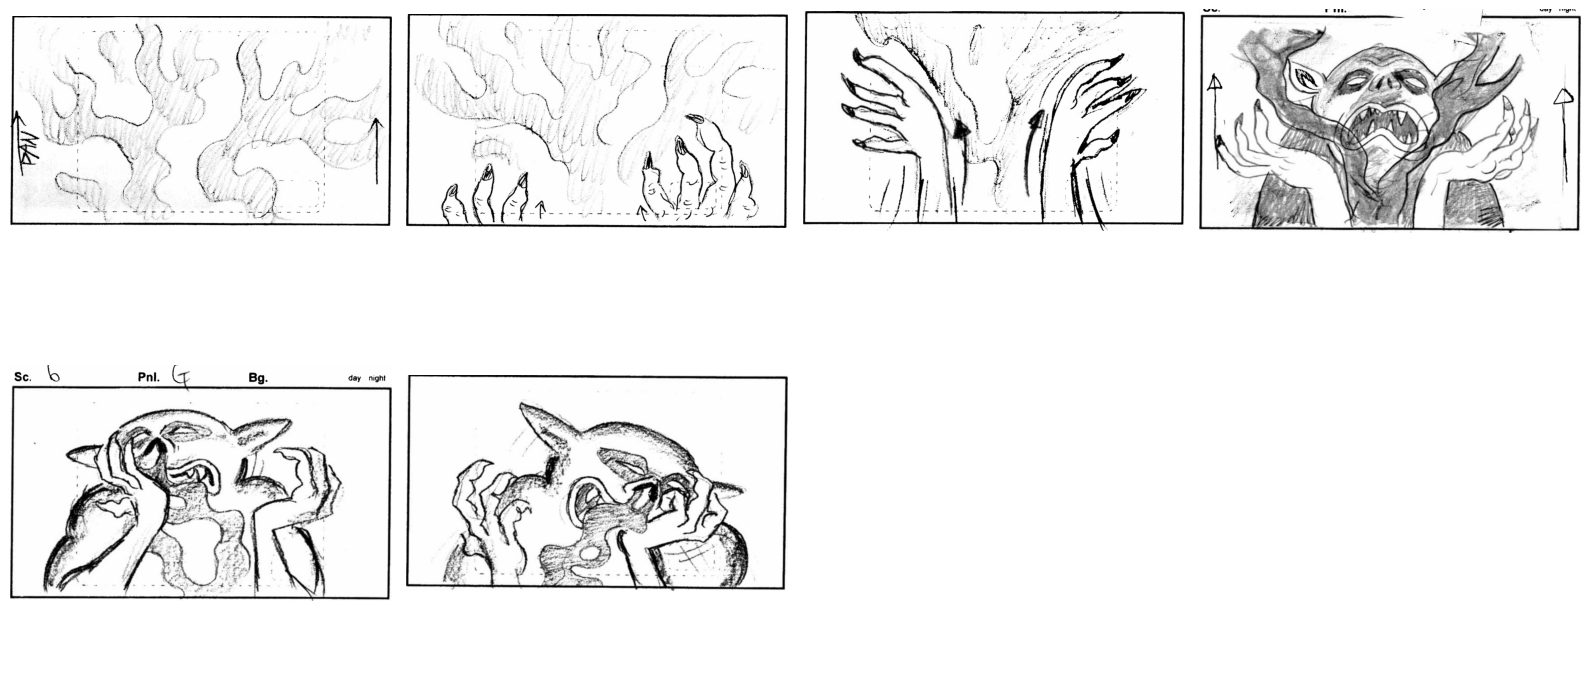

['/content/drive/MyDrive/project/panels/seq01_panel001.png',
 '/content/drive/MyDrive/project/panels/seq01_panel002.png',
 '/content/drive/MyDrive/project/panels/seq01_panel003.png',
 '/content/drive/MyDrive/project/panels/seq01_panel004.png',
 '/content/drive/MyDrive/project/panels/seq01_panel005.png',
 '/content/drive/MyDrive/project/panels/seq01_panel006.png']

In [ ]:
# --- Example: inspect one page and crop it. Edit to match your files. ---
page_paths = sorted(glob.glob(os.path.join(STORYBOARD_DIR, '*.png')) +
                    glob.glob(os.path.join(STORYBOARD_DIR, '*.jpg')))
print(len(page_paths), 'files found')

page = load_rgb(page_paths[0])
print('page size (w, h):', page.size)

# Option A: grid split
# panels = split_grid(page, rows=3, cols=2, margin=10)
# Option B: auto-detect
# panels, boxes = detect_panels(page)
# Option C: manual boxes (left, upper, right, lower)
# panels = [page.crop((100, 50, 700, 450)), page.crop((720, 50, 1320, 450))]

# show(panels)
#save_panels(panels, 'seq01')

KEEP = slice(1, 3)   # the two middle panels of the four detected

all_panels = []      # (page_number, panel_image) in reading order
for pno, pp in enumerate(page_paths, 1):
    page = load_rgb(pp)
    panels, boxes = detect_panels(page)
    if len(panels) != 4:
        print(f'page {pno}: detected {len(panels)} panels, check this one manually')
        continue
    for p in panels[KEEP]:
        all_panels.append((pno, p))

print(len(all_panels), 'relevant panels')
show([p for _, p in all_panels[:8]], cols=4)


# e.g. pages 1-3 form one scene
scene_panels = [p for pno, p in all_panels if 1 <= pno <= 3]
save_sequence(scene_panels, 'seq01')

## 3. Conditioning map extraction
ControlNet's canny model expects **white lines on black**. Storyboards are usually dark lines on white, so try both modes and compare.

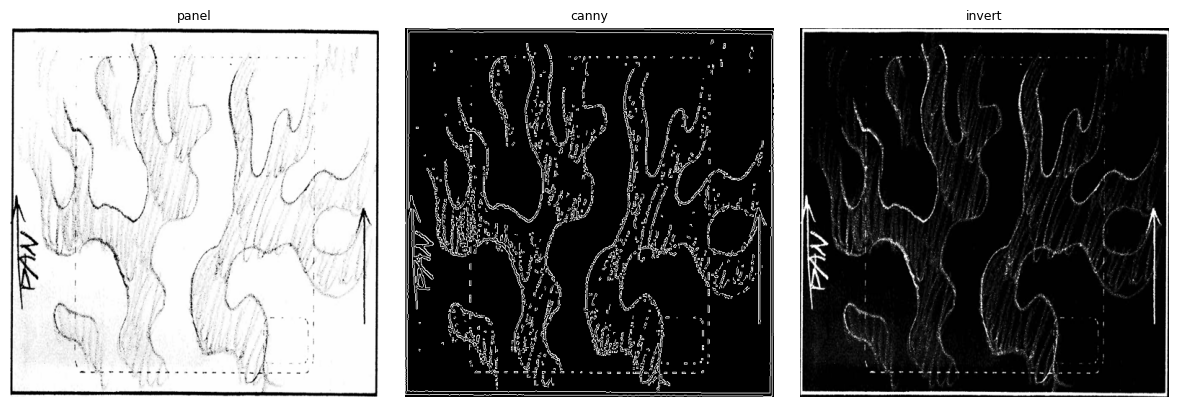

In [ ]:
def make_condition(img, mode='canny', size=512, low=100, high=200):
    img = img.resize((size, size))   # same resize for every panel and every method
    gray = np.array(img.convert('L'))
    if mode == 'canny':
        cond = cv2.Canny(gray, low, high)
    elif mode == 'invert':
        cond = 255 - gray            # dark lines on white -> white lines on black
    else:
        raise ValueError(mode)
    return Image.fromarray(cond).convert('RGB')

# Quick comparison on one panel (run after you've saved some panels)
panel_paths = sorted(glob.glob(os.path.join(PANEL_DIR, '*.png')))
if panel_paths:
    test = load_rgb(panel_paths[0])
    show([test.resize((512, 512)),
          make_condition(test, 'canny'),
          make_condition(test, 'invert')],
         titles=['panel', 'canny', 'invert'], cols=3)

## 4. Load ControlNet

In [ ]:
from diffusers import StableDiffusionControlNetPipeline, ControlNetModel, UniPCMultistepScheduler

controlnet = ControlNetModel.from_pretrained(CONFIG['controlnet'], torch_dtype=torch.float16)
pipe = StableDiffusionControlNetPipeline.from_pretrained(
    CONFIG['base_model'], controlnet=controlnet, torch_dtype=torch.float16
).to('cuda')
pipe.scheduler = UniPCMultistepScheduler.from_config(pipe.scheduler.config)
pipe.set_progress_bar_config(disable=True)

Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/996 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.45GB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

## 5. Sequence generation loop
Each sequence is a list of panel files plus one text prompt per panel. The seed is reset for every panel so differences between methods come from the method, not the noise. Outputs and the exact config are saved together.

In [ ]:
def run_sequence(seq_name, panel_files, prompts, method='controlnet_baseline', cfg=CONFIG):
    assert len(panel_files) == len(prompts), 'need one prompt per panel'
    out_dir = os.path.join(OUTPUT_DIR, method, seq_name)
    os.makedirs(out_dir, exist_ok=True)

    results = []
    for i, (pf, prompt) in enumerate(zip(panel_files, prompts), 1):
        cond = make_condition(load_rgb(pf), cfg['cond_mode'], cfg['resolution'],
                              cfg['canny_low'], cfg['canny_high'])
        gen = torch.Generator('cuda').manual_seed(cfg['seed'])
        img = pipe(
            prompt=f"{prompt}, {cfg['prompt_suffix']}",
            negative_prompt=cfg['negative_prompt'],
            image=cond,
            num_inference_steps=cfg['steps'],
            guidance_scale=cfg['guidance_scale'],
            controlnet_conditioning_scale=cfg['controlnet_conditioning_scale'],
            generator=gen,
        ).images[0]
        img.save(os.path.join(out_dir, f'panel{i:02d}.png'))
        cond.save(os.path.join(out_dir, f'panel{i:02d}_cond.png'))
        results.append(img)

    record = {"method": method, "sequence": seq_name, "panel_files": panel_files,
              "prompts": prompts, "config": cfg, "timestamp": time.strftime('%Y-%m-%d %H:%M:%S'),
              "torch": torch.__version__}
    with open(os.path.join(out_dir, 'run_config.json'), 'w') as f:
        json.dump(record, f, indent=2)
    return results

# --- Define a sequence: same character described the same way in every prompt ---
seq_name = 'seq01'
panel_files = sorted(glob.glob(os.path.join(PANEL_DIR, f'{seq_name}_panel*.png')))
CHAR = "a vampire"
SETTING = "blank background"
#6 panels
actions = [
    "jelly vaporizes as camera pans up",
    "vampire hands slowly come into screen, close-up",
    "hands rapidly push vaporized blood upwards, close-up",
    "camera pans upto vampire's face, close-up",
    "vampire inhales jelly mist from right hand, close-up",
    "vampire inhales jelly mist from left hand, close-up",
]
prompts = [f"{CHAR}, {a}, {SETTING}" for a in actions][:len(panel_files)]

if panel_files:
    frames = run_sequence(seq_name, panel_files, prompts)

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


## 6. Side-by-side preview (storyboard vs. generated)

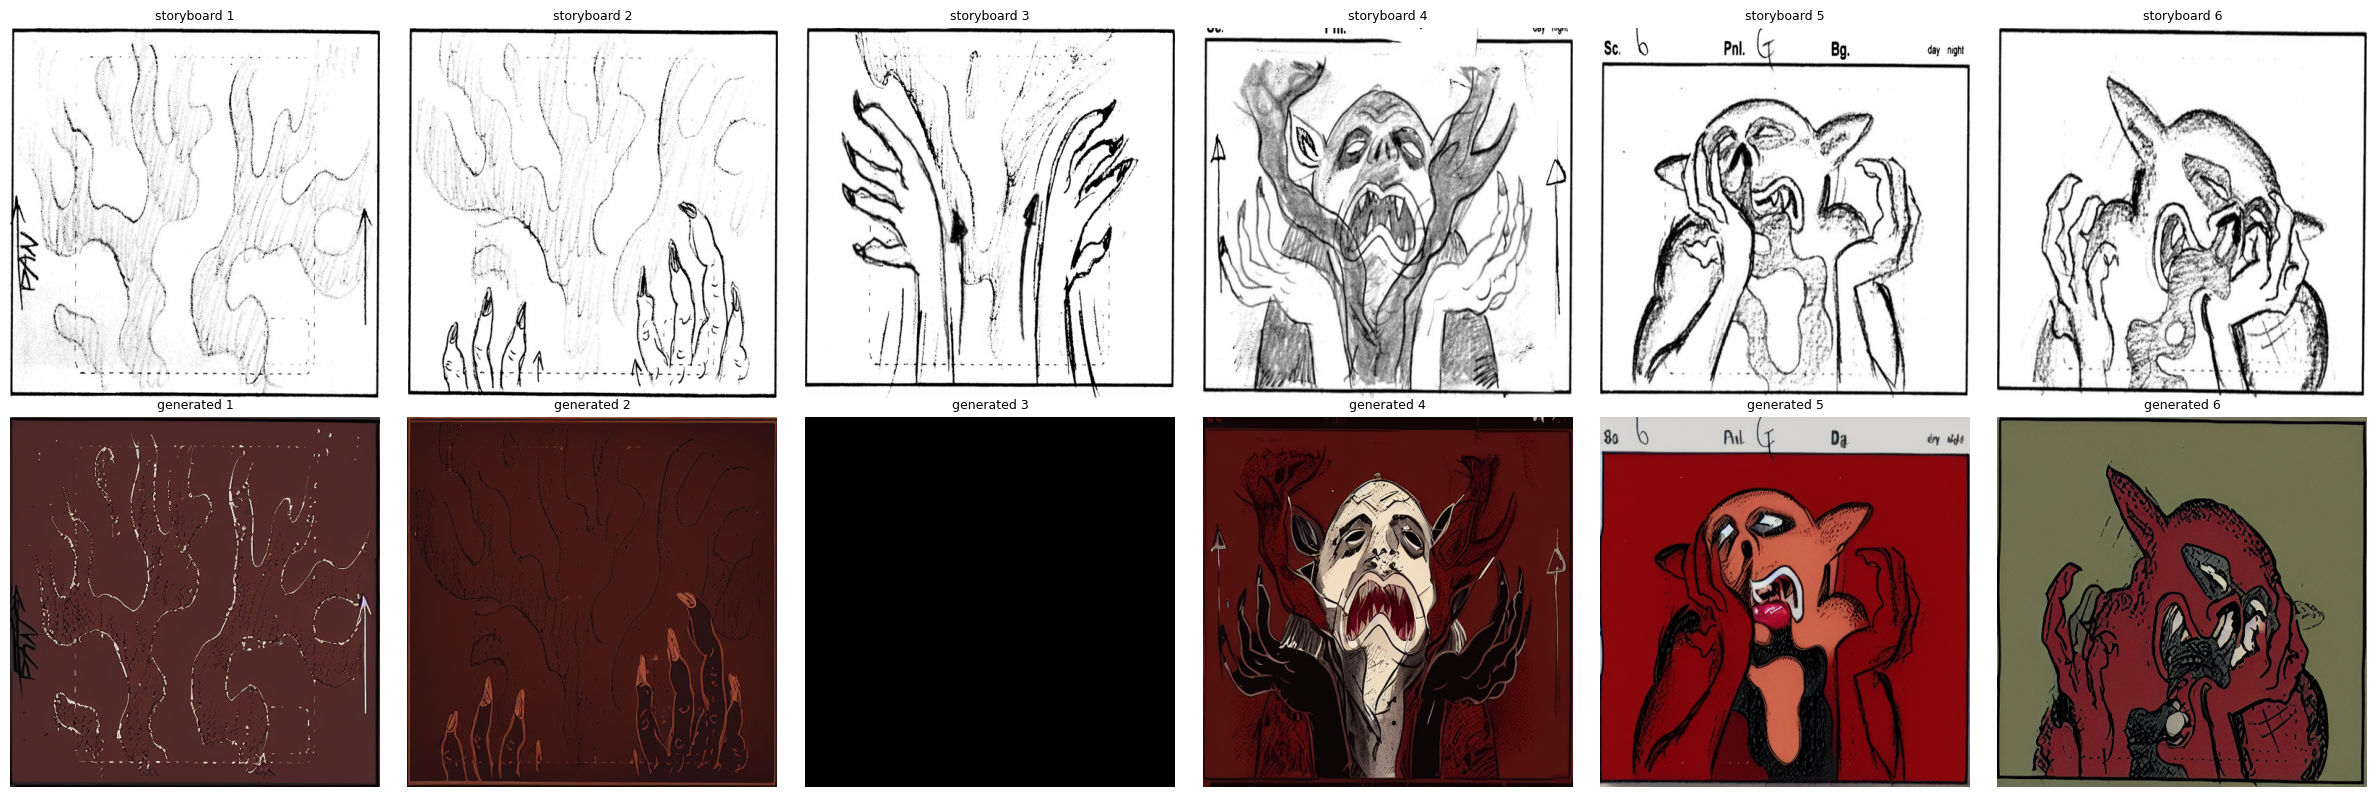

In [ ]:
if panel_files:
    originals = [load_rgb(p).resize((CONFIG['resolution'],)*2) for p in panel_files]
    show(originals + frames,
         titles=[f'storyboard {i+1}' for i in range(len(originals))] +
                [f'generated {i+1}' for i in range(len(frames))],
         cols=len(frames))

## 7. Character reference crops
For IP-Adapter later, save a clean crop of each main character (from the storyboards or model sheets if available). Use the grid overlay to read pixel coordinates.

In [ ]:
def grid_view(img, figsize=(12, 12)):
    plt.figure(figsize=figsize); plt.imshow(img); plt.grid(True, alpha=0.4); plt.show()

def save_ref(img, box, name):
    crop = img.crop(box)
    path = os.path.join(REF_DIR, f'{name}.png')
    crop.save(path); return crop

# grid_view(page)
# ref = save_ref(page, (120, 80, 420, 480), 'fox_front')   # EDIT box
# ref

## 8. Hooks for the other methods
Reuse `run_sequence`'s structure (same panels, prompts, seed, config, saved `run_config.json`) for each method so outputs are directly comparable:

- **IP-Adapter:** `pipe.load_ip_adapter(...)`, then pass a reference crop from `REF_DIR` as `ip_adapter_image`. Supported in `diffusers`.
- **StoryDiffusion:** official repo (`HVision-NKU/StoryDiffusion`), Consistent Self-Attention; generates panels as a batch.
- **ConsiStory:** official repo (`NVlabs/consistory`), training-free shared attention across a batch.
- **The Chosen One:** iterative identity clustering; much heavier compute, so decide early whether it's feasible on Colab.

Check each repo's README for its memory requirements and whether it can take a ControlNet layout condition, since this affects how fair the comparison is.